# Get Data

In [1]:
import pandas as pd
df_base = pd.read_parquet("../data/processed/comtrade_441012_base.parquet")
print(f"df Shape: {df_base.shape}")
df_base.head(3)

df Shape: (25589, 61)


,record_id,hs_code_short,reporter_code,partner_code,commodity_code,year,flow_code,unit_code,value_usd,reported_currency,...,quantity_estimated,weight_estimated,year_date,hs_mismatch,price_per_kg,calc_kg_per_usd,reporter_continent,partner_continent,recovered_kg_from_sup,netweight_kg
0,80630069,H3,100,124,441012,2011,1,8,319186,BGN,...,False,False,2011-01-01,False,0.440319,2.271080,Europe,North America,False,724897.0
1,80630182,H3,100,156,441012,2011,1,8,171644,BGN,...,False,False,2011-01-01,False,0.526677,1.898697,Europe,Asia,False,325900.0
2,80630489,H3,100,196,441012,2011,2,8,518550,BGN,...,False,False,2011-01-01,False,0.442542,2.259674,Europe,Asia,False,1171754.0


In [1]:
from vacoda.io.loaders import load_processed_trade_data
import pandas as pd
df_base = load_processed_trade_data()
print("shape of df_base:", df_base.shape)
df_base.head(2)

shape of df_base: (1582656, 62)


,record_id,hs_code_short,reporter_code,partner_code,commodity_code,year,flow_code,unit_code,value_usd,reported_currency,...,weight_estimated,year_date,hs_mismatch,price_per_kg,calc_kg_per_usd,reporter_continent,partner_continent,partner_reliability,recovered_kg_from_sup,netweight_kg
0,80630069,H3,100,124,441012,2011,1.0,8,319186.0,BGN,...,False,2011-01-01,False,0.440319,2.271080,Europe,North America,high,False,724897.0
1,80630182,H3,100,156,441012,2011,1.0,8,171644.0,BGN,...,False,2011-01-01,False,0.526677,1.898697,Europe,Asia,high,False,325900.0


In [2]:
df_base.columns.to_list()

['record_id',
 'hs_code_short',
 'reporter_code',
 'partner_code',
 'commodity_code',
 'year',
 'flow_code',
 'unit_code',
 'value_usd',
 'reported_currency',
 'conversion_factor',
 'netweight_kg_raw',
 'sup_quantity',
 'estimation_code',
 'reported_hs_code_short',
 'CD_HT',
 'partner_source',
 'valuation',
 'old_flow_code',
 'CD_UnitMult',
 'CD_Decimals',
 'CD_IDUpload',
 'CD_IDReporter',
 'CD_IDPartner',
 'CD_IDCommodity',
 'CD_IDUnit',
 'CD_as_reported',
 'kg_per_usd',
 'CD_ActionType',
 'reporter_country_code',
 'reporter_country_name',
 'reporter_country_iso2',
 'reporter_country_iso3',
 'reporter_country_valid_from',
 'reporter_country_valid_until',
 'partner_country_code',
 'partner_country_name',
 'partner_country_iso2',
 'partner_country_iso3',
 'partner_country_valid_from',
 'partner_country_valid_until',
 'hs_valid_from',
 'hs_valid_until',
 'hs_version_name',
 'commodity_description',
 'flow_description',
 'flow_category',
 'unit_short_name',
 'unit_description',
 'estimati

In [2]:
df_base[df_base['flow_code'].isin([3, 4])][["flow_description", "flow_code", "flow_category", 'partner_source']].value_counts()

flow_description  flow_code  flow_category  partner_source                 
Re-import         4.0        X              origin                             0
RE-Imports        4.0        M              Consignment                        0
                                            Consumption                        0
                                            Last Known Destination             0
                                            Last known Destination             0
                                                                              ..
Re-import         3.0        X              Origin/Consignment for Intra-EU    0
                                            Purchase                           0
                                            Sale                               0
                                            consignment                        0
                                            origin                             0
Name: count, Length: 616, dtype: 

## Flow Description Diagnostics

In [3]:
df_base.groupby(["flow_description"]).size()

flow_description
Domestic Export                                  8
Export                                           8
Export of goods after inward processing          8
Export of goods for outward processing           8
Exports                                     732368
Foreign Import                                   8
Import                                           8
Import of goods after outward processing         8
Import of goods for inward processing            8
Imports                                     785553
RE-Exports                                   58691
RE-Imports                                    5964
Re-export                                        8
Re-import                                        8
dtype: int64

## Flow Diagnostics

In [4]:
df_base['flow_description'].value_counts(dropna=False, normalize=True) * 100

flow_description
Imports                                     49.635107
Exports                                     46.274617
RE-Exports                                   3.708386
RE-Imports                                   0.376835
Domestic Export                              0.000505
Export                                       0.000505
Export of goods after inward processing      0.000505
Export of goods for outward processing       0.000505
Foreign Import                               0.000505
Import                                       0.000505
Import of goods after outward processing     0.000505
Import of goods for inward processing        0.000505
Re-export                                    0.000505
Re-import                                    0.000505
Name: proportion, dtype: float64

In [16]:
df_base.groupby(["flow_description", "flow_code"]).size().reset_index(
    name="count"
).sort_values("count", ascending=False)

,flow_description,flow_code,count
1,Imports,1.0,785553
0,Exports,2.0,732368
2,RE-Exports,3.0,58691
3,RE-Imports,4.0,5964


In [17]:
counts = (
    df_base.groupby(["flow_description", "flow_code"]).size().reset_index(name="count")
)
print("Sum of counts:", counts["count"].sum())
print("df_base rows: ", len(df_base))
print("Match:", counts["count"].sum() == len(df_base))

Sum of counts: 1582576
df_base rows:  1582656
Match: False


In [18]:
print("NaN in flow_description:", df_base["flow_description"].isna().sum())
print("NaN in flow_code: ", df_base["flow_code"].isna().sum())
print(
    "NaN in either: ",
    (df_base["flow_description"].isna() | df_base["flow_code"].isna()).sum(),
)

NaN in flow_description: 0
NaN in flow_code:  80
NaN in either:  80


In [5]:
df_base["flow_code"].value_counts(dropna=False, normalize=True) * 100

flow_code
1.0    49.635107
2.0    46.274617
3.0     3.708386
4.0     0.376835
NaN     0.005055
Name: proportion, dtype: float64

In [13]:
df_base[~df_base["flow_code"].isin([1, 2, 3, 4])]["partner_source"].value_counts(
    dropna=False, normalize=True) * 100

partner_source
NaN                                100.0
Consignment                          0.0
Consumption                          0.0
Last Known Destination               0.0
Last known Destination               0.0
Last known destination               0.0
Origin                               0.0
Origin/Consignment for Intra-EU      0.0
Purchase                             0.0
Sale                                 0.0
consignment                          0.0
origin                               0.0
Name: proportion, dtype: float64

In [18]:
df_base.groupby(["flow_description", "partner_source"]).size()

flow_description  partner_source                 
Exports           Consignment                         123
                  Last Known Destination             6422
                  Sale                                  4
Imports           Consignment                         312
                  Origin                             4585
                  Origin/Consignment for Intra-EU    1331
                  Purchase                             17
dtype: int64

In [7]:
import pandas as pd
import re

def normalize_text_basic(s: pd.Series) -> pd.Series:
    out = s.astype("string").str.strip().str.lower()
    out = out.str.replace(r"\s+", " ", regex=True)
    return out

In [8]:
def harmonize_partner_source(s: pd.Series) -> pd.DataFrame:
    raw = s.astype("string")
    norm = normalize_text_basic(s)

    exact_map = {
        "origin": "Origin",
        "origin/consignment for intra-eu": "Origin/Consignment for Intra-EU",
        "consignment": "Consignment",
        "purchase": "Purchase",
        "sale": "Sale",
        "consumption": "Consumption",
        "last known destination": "Last Known Destination",
    }

    rule_map = {
        "last known destinations": "Last Known Destination",
        "origins": "Origin",
        "consignment for intra-eu": "Consignment for Intra-EU",
    }

    final = raw.copy()
    status = pd.Series(pd.NA, index=s.index, dtype="string")

    missing_mask = raw.isna()
    exact_mask   = norm.isin(exact_map)
    rule_mask    = norm.isin(rule_map)

    final.loc[exact_mask] = norm.loc[exact_mask].map(exact_map)
    final.loc[rule_mask]  = norm.loc[rule_mask].map(rule_map)

    status.loc[missing_mask]  = "missing"
    status.loc[exact_mask]    = "mapped_exact"
    status.loc[rule_mask]     = "mapped_rule"
    status.loc[status.isna()] = "unmapped"

    return pd.DataFrame(
        {
            "partner_source_raw"    : raw,
            "partner_source_norm"   : norm,
            "partner_source_clean"  : final,
            "partner_source_status" : status,
        }
    )

In [9]:
df_base['partner_source'].value_counts(dropna=False, normalize=True) * 100

partner_source
NaN                                34.170028
Last Known Destination             31.348379
Origin                             26.709910
Origin/Consignment for Intra-EU     3.385764
Consignment                         2.997872
Purchase                            0.787853
Sale                                0.407290
Consumption                         0.145452
origin                              0.017945
consignment                         0.012574
Last known Destination              0.008972
Last known destination              0.007961
Name: proportion, dtype: float64

In [12]:
harmonize_df = harmonize_partner_source(df_base["partner_source"])
harmonize_df["partner_source_status"].value_counts(dropna=False, normalize=True) * 100  

partner_source_status
mapped_exact    65.829972
missing         34.170028
Name: proportion, dtype: double[pyarrow]

In [11]:
harmonize_df.loc[
    harmonize_df["partner_source_status"] == "mapped_exact",
    ["partner_source_raw", "partner_source_clean"],
].drop_duplicates()

,partner_source_raw,partner_source_clean
0,Origin,Origin
2,Consignment,Consignment
33,Last Known Destination,Last Known Destination
74,Origin/Consignment for Intra-EU,Origin/Consignment for Intra-EU
4426,Sale,Sale
4672,Purchase,Purchase
49266,Consumption,Consumption
99095,Last known Destination,Last Known Destination
140474,consignment,Consignment
188903,origin,Origin


In [9]:
df_base.groupby(["flow_description", "partner_source"]).size()

flow_description  partner_source                 
Exports           Consignment                         123
                  Last Known Destination             6422
                  Sale                                  4
Imports           Consignment                         312
                  Origin                             4585
                  Origin/Consignment for Intra-EU    1331
                  Purchase                             17
dtype: int64

## Data Diagnositcs

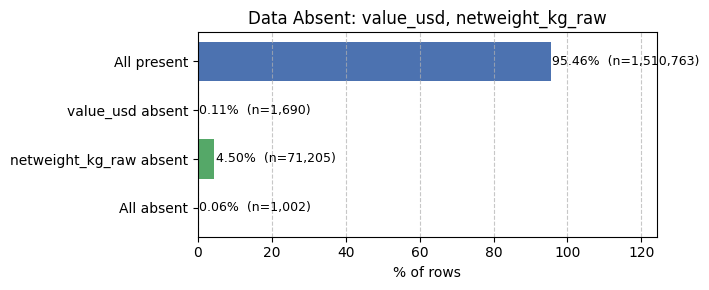

In [4]:
from vacoda.visualization.distributions import plot_data_coverage_bar, plot_data_coverage_pie
plot_data_coverage_bar(df_base, cols=["value_usd", "netweight_kg_raw"], indicator="absence")

In [86]:
assess_weight_recoverability(
    df_base,
    weight_col="netweight_kg",
    sup_col="sup_quantity",
    unit_col="unit_code",
)

total_rows                                             25589.000000
missing_weight_percentage_total                            1.555356
missing_weight_n                                         398.000000
recoverable_direct_percentage_total                        0.429872
recoverable_direct_n                                     110.000000
potentially_recoverable_nonkg_percentage_total             0.085974
potentially_recoverable_nonkg_n                           22.000000
recoverable_direct_percentage_of_missing                  27.638191
potentially_recoverable_nonkg_percentage_of_missing        5.527638
dtype: float64

In [61]:
has_weight = df_base["netweight_kg"].notna() & (df_base["netweight_kg"] > 0)
list_cols = ['netweight_kg', 'sup_quantity', 'unit_code']
df_base[~has_weight & df_base['sup_quantity'].notna() & (df_base['sup_quantity'] > 0) &
        (df_base['unit_code'] > 1) & 
        (df_base['unit_code'] != 8)][list_cols].shape

(22, 3)

In [33]:
df_base[
    df_base["netweight_kg"].notna()
    & df_base["sup_quantity"].notna()
    & (df_base["unit_code"] == 12)
][['netweight_kg', 'sup_quantity', 'unit_code']]

,netweight_kg,sup_quantity,unit_code
719,0.0,38.0,12
902,0.0,50.0,12
2938,0.0,75.0,12
3354,0.0,33.0,12
3986,0.0,1978.0,12
22163,0.0,124.0,12
22164,0.0,124.0,12


In [32]:
mask_m3_with_both = (
    df_base["netweight_kg"].notna()
    & (df_base["netweight_kg"] > 0)
    & df_base["sup_quantity"].notna()
    & (df_base["sup_quantity"] > 0)
    & (df_base["unit_code"] == 12)
)

df_base.loc[mask_m3_with_both, "kg_per_m3"] = (
    df_base.loc[mask_m3_with_both, "netweight_kg"]
    / df_base.loc[mask_m3_with_both, "sup_quantity"]
)

In [4]:
import numpy as np
np.where(
    df_base["flow_code"] == "M",
    "CIF_like",
    np.where(df_base["flow_code"] == "X", "FOB_like", "unknown"),
)

array(['unknown', 'unknown', 'unknown', ..., 'unknown', 'unknown',
       'unknown'], shape=(25589,), dtype='<U8')

## Italy-USA Discreprency

In [8]:
country1 = "Italy"
country2 = "USA"
base_cols = [
    "reporter_country_name",
    "partner_country_name",
    "flow_description",
    "value_usd",
    "price_per_kg",
    "year",
    "netweight_kg",
    "valuation",
    "partner_source",
]
df_base[
    (df_base["reporter_country_name"] == country1)
    & (df_base["partner_country_name"] == country2)
][base_cols].sort_values("year").head(10)

,reporter_country_name,partner_country_name,flow_description,value_usd,price_per_kg,year,netweight_kg,valuation,partner_source
15033,Italy,USA,Exports,270213,5.758156,2007,46927.0,FOB,Last Known Destination
15032,Italy,USA,Imports,161861,0.385877,2007,419463.0,CIF,Origin/Consignment for Intra-EU
9021,Italy,USA,Exports,19744,21.367965,2008,924.0,FOB,Last Known Destination
9610,Italy,USA,Imports,1487248,0.331300,2008,4489130.0,CIF,Origin/Consignment for Intra-EU
9290,Italy,USA,Imports,333603,0.372885,2009,894655.0,CIF,Origin/Consignment for Intra-EU
9611,Italy,USA,Exports,39143,0.524564,2009,74620.0,FOB,Last Known Destination
9181,Italy,USA,Imports,331376,0.393818,2010,841444.0,CIF,Origin/Consignment for Intra-EU
9050,Italy,USA,Exports,29483,4211.857143,2010,7.0,FOB,Last Known Destination
9183,Italy,USA,Exports,74641,99.787433,2011,748.0,FOB,Last Known Destination
9182,Italy,USA,Imports,258825,0.353144,2011,732917.0,CIF,Origin/Consignment for Intra-EU


In [9]:
df_base[
    (df_base["reporter_country_name"] == country2)
    & (df_base["partner_country_name"] == country1)
][base_cols].sort_values("year").head(10)

,reporter_country_name,partner_country_name,flow_description,value_usd,price_per_kg,year,netweight_kg,valuation,partner_source
25471,USA,Italy,Exports,260651,0.349778,2007,745190.0,FOB,Last Known Destination
23652,USA,Italy,Exports,757647,0.352944,2008,2146651.0,FOB,Last Known Destination
24879,USA,Italy,Imports,7638,0.268000,2009,28500.0,CIF,Origin
23653,USA,Italy,Exports,195423,0.298992,2009,653607.0,FOB,Last Known Destination
24880,USA,Italy,RE-Exports,3118,2.398462,2009,1300.0,NaN,NaN
24143,USA,Italy,Exports,196733,0.352700,2010,557791.0,FOB,Last Known Destination
21303,USA,Italy,Exports,161952,0.408380,2011,396572.0,FOB,Last Known Destination
21304,USA,Italy,RE-Exports,38325,1.936780,2011,19788.0,NaN,NaN
24881,USA,Italy,Imports,24489,0.959074,2015,25534.0,CIF,Origin
21305,USA,Italy,Imports,53679,0.746288,2016,71928.0,NaN,NaN


## Bahamas-USA Discreprency


In [11]:
country1="USA"
country2 = 'Bahamas'
base_cols=["reporter_country_name","partner_country_name","flow_description",
        "value_usd", "price_per_kg","year", "netweight_kg","valuation","partner_source"
    ]
df_base[(df_base["reporter_country_name"] == country2)
    & (df_base["partner_country_name"] == country1)
][base_cols].sort_values("year").head(5)

,reporter_country_name,partner_country_name,flow_description,value_usd,price_per_kg,year,netweight_kg,valuation,partner_source
10936,Bahamas,USA,Imports,8032,4016.00,2009,2.0,CIF,Origin
10763,Bahamas,USA,Imports,10986,109.86,2010,100.0,CIF,Origin
10783,Bahamas,USA,Imports,7787,3893.50,2011,2.0,CIF,Origin
10825,Bahamas,USA,Imports,8305,8305.00,2012,1.0,CIF,Origin
10937,Bahamas,USA,Imports,25,NaN,2013,0.0,CIF,NaN


In [12]:
# make it sort by year
df_base[
    (df_base["reporter_country_name"] == country1)
    & (df_base["partner_country_name"] == country2)
][base_cols].sort_values("year").head(5)

,reporter_country_name,partner_country_name,flow_description,value_usd,price_per_kg,year,netweight_kg,valuation,partner_source
23863,USA,Bahamas,Exports,12271,1.352623,2009,9072.0,FOB,Last Known Destination
21875,USA,Bahamas,Exports,7070,0.572470,2011,12350.0,FOB,Last Known Destination
25022,USA,Bahamas,Exports,24045,0.704884,2015,34112.0,FOB,Last Known Destination
21876,USA,Bahamas,Exports,45844,0.630852,2016,72670.0,NaN,NaN
21877,USA,Bahamas,Exports,25000,1.413228,2017,17690.0,NaN,NaN


In [13]:
print(df_base['netweight_kg'].isna().sum(), df_base['value_usd'].isna().sum() )

372 0


In [50]:
mismatch = df_base[df_base["netweight_kg"].notna() ^ df_base["value_usd"].notna()]
print("Mismatch rows:", len(mismatch))
mismatch[["netweight_kg", "value_usd"]].head(20)


Mismatch rows: 372


,netweight_kg,value_usd
410,NaN,73087
411,NaN,73087
491,NaN,117
668,NaN,29102166
672,NaN,290
683,NaN,4256
1173,NaN,51
1246,NaN,107
2189,NaN,268411
2193,NaN,16070


In [20]:
print("netweight present, value missing:", ((df_base["netweight_kg"].notna()) & (df_base["value_raw"].isna())).sum())
print("value present, netweight missing:", ((df_base["value_raw"].notna()) & (df_base["netweight_kg"].isna())).sum())

netweight present, value missing: 0
value present, netweight missing: 372


In [21]:
## both missing
print("Both netweight and value missing:", ((df_base["netweight_kg"].isna()) & (df_base["value_raw"].isna())).sum())

Both netweight and value missing: 0


In [22]:
target_mask = (
    df_base["netweight_kg"].isna()
    & df_base["value_raw"].notna()
    & (df_base["value_raw"] > 0)
)

target_mask.sum()

np.int64(372)

In [23]:
df_base['reported_currency'].value_counts(normalize=True) * 100

reported_currency
USD    47.559547
EUR    27.668879
CAD     3.209684
DKK     1.811792
GBP     1.772745
         ...    
BWP     0.015619
AWG     0.007809
PGK     0.007809
YER     0.007809
BND     0.007809
Name: proportion, Length: 75, dtype: float64

In [24]:
df_base[['reported_currency', 'conversion_factor','value_raw']] 

,reported_currency,conversion_factor,value_raw
0,BGN,0.711723,319186
1,BGN,0.711723,171644
2,BGN,0.711969,518550
3,NaN,NaN,684637
4,NaN,NaN,10976
...,...,...,...
25584,NaN,NaN,7910
25585,USD,1.000000,737
25586,NaN,NaN,6362
25587,ZMK,0.162468,741


In [25]:
df_base[df_base['reported_currency']== 'USD'][['reported_currency', 'conversion_factor','value_raw']] 

,reported_currency,conversion_factor,value_raw
63,USD,1.0,2363100
118,USD,1.0,11300
121,USD,1.0,92500
134,USD,1.0,900
140,USD,1.0,28900
...,...,...,...
25572,USD,1.0,2261877
25574,USD,1.0,90111
25575,USD,1.0,59795
25583,USD,1.0,3400


## Boxplot of value_usd

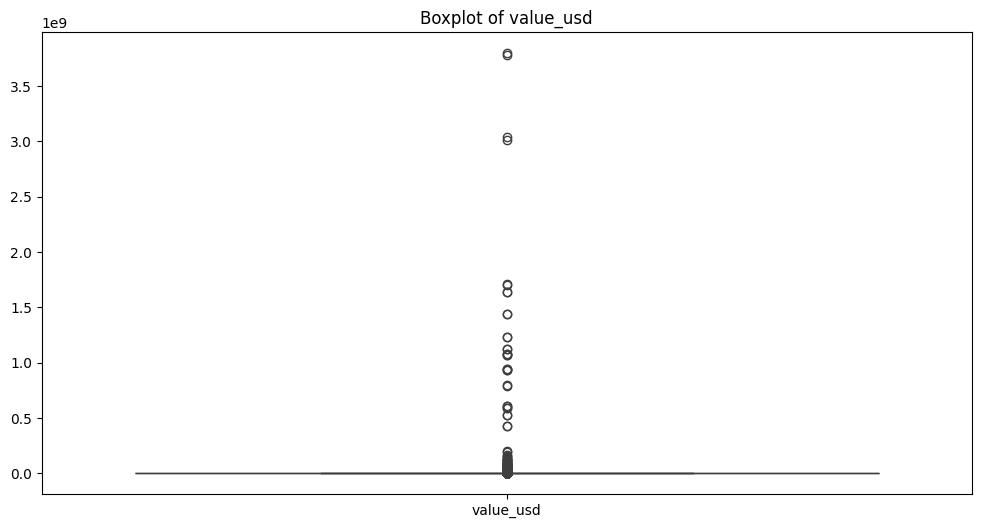

In [3]:
## Lets draw boxplot of both log of both value_raw and value_norm to check for outliers
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(12, 6))
sns.boxplot(data=df_base[['value_usd']])
plt.title('Boxplot of value_usd')
plt.show()

# unit_code Issue

In [ ]:
## First subset the data to only include the columns that are relevant for unit standardization. This will make the process more efficient and easier to manage.
cols = [
    "hs_code_short",
    "unit_code",
    "value_raw",
    "netweight_kg",
    "kg_per_usd",
    "calc_price_per_kg",
    "is_estimated",
    "weight_estimated",
    "quantity_estimated",
    "flow_code",
    "reporter_country_name",
    "partner_country_name",
    "year",
    "flow_description",
    "valuation",
    "partner_source"
]

df = df_base[cols].copy()

In [ ]:
df.head(20)

,unit_code,value_raw,netweight_kg,calc_kg_per_usd,kg_per_usd,calc_price_per_kg,is_estimated,weight_estimated,quantity_estimated,commodity_code,reporter_country_name,partner_country_name,year,flow_description,valuation
0,8,319186,724897.0,2.271080,2.271080,0.440319,False,False,False,441012,Bulgaria,Canada,2011,NaN,CIF
1,8,171644,325900.0,1.898697,1.898697,0.526677,False,False,False,441012,Bulgaria,China,2011,NaN,CIF
2,8,518550,1171754.0,2.259674,2.259674,0.442542,False,False,False,441012,Bulgaria,Cyprus,2011,NaN,FOB
3,8,684637,1519340.0,2.219191,2.219191,0.450615,False,False,False,441012,Bulgaria,Cyprus,2018,NaN,NaN
4,8,10976,22460.0,2.046283,2.046283,0.488691,False,False,False,441012,Bulgaria,Czechia,2018,NaN,NaN
5,8,149324,272424.0,1.824382,1.824382,0.548131,False,False,False,441012,Bulgaria,Georgia,2011,NaN,FOB
6,8,48203,56966.0,1.181794,1.181794,0.846171,False,False,False,441012,Bulgaria,Germany,2011,NaN,CIF
7,8,307,351.0,1.143322,1.143322,0.874644,False,False,False,441012,Bulgaria,Germany,2017,NaN,NaN
8,8,31097,69145.0,2.223526,2.223526,0.449736,False,False,False,441012,Bulgaria,Germany,2018,NaN,NaN
9,8,105188,404717.0,3.847559,3.847559,0.259905,False,False,False,441012,Bulgaria,Greece,2011,NaN,CIF


In [ ]:
## Lets find all columns that have unit in their name
unit_columns = [col for col in df.columns if "unit" in col]
unit_columns

['unit_code']

In [ ]:
df[unit_columns]

,unit_code
0,8
1,8
2,8
3,8
4,8
...,...
25584,8
25585,8
25586,8
25587,8


In [ ]:
df['unit_code'].isna().sum()

np.int64(0)

In [ ]:
df['unit_code'].value_counts()

unit_code
8     25302
1       263
12       24
Name: count, dtype: int64

## Unit_code distribution

<Axes: xlabel='unit_code'>

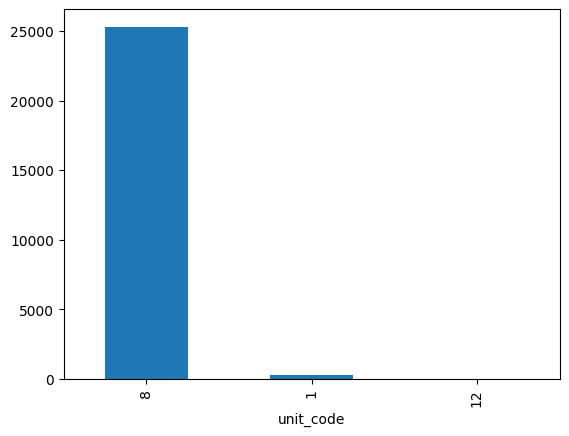

In [ ]:
df['unit_code'].value_counts().plot(kind='bar')

In [ ]:
df['is_estimated'].value_counts(normalize=True) * 100

is_estimated
False    88.29966
True     11.70034
Name: proportion, dtype: float64

In [ ]:
df.columns.to_list()

['unit_code',
 'value_raw',
 'netweight_kg',
 'calc_kg_per_usd',
 'kg_per_usd',
 'calc_price_per_kg',
 'is_estimated',
 'weight_estimated',
 'quantity_estimated',
 'commodity_code',
 'reporter_country_name',
 'partner_country_name',
 'year',
 'flow_description',
 'valuation']

In [ ]:
## how many rows have unit_code == 1 and price_per_kg is not null?
df[(df['unit_code'] == 1) & (df['kg_per_usd'].notnull())][['calc_price_per_kg', 'netweight_kg']]

,calc_price_per_kg,netweight_kg
141,0.425333,3000.0
437,NaN,0.0
669,NaN,0.0
2937,NaN,0.0
3353,NaN,0.0
3985,NaN,0.0
4596,2.058724,5313.0
4738,1.467742,434.0
7055,118.000000,1.0
14052,1.899171,724.0


In [ ]:
## Lets check if the columns are constant throughout the dataframe
constant_columns = [col for col in df.columns if df[col].nunique() == 1]
constant_columns

['commodity_code']

In [ ]:
## Lets remove the constant columns from the dataframe
df = df.drop(columns=constant_columns)
print("Shape of the dataframe after removing constant columns:", df.shape)

Shape of the dataframe after removing constant columns: (25589, 14)


In [ ]:
## Lets find the columns that have more than 80% missing values
missing_value_threshold = 0.8
missing_value_columns = [col for col in df.columns if df[col].isna().mean() > missing_value_threshold]
missing_value_columns

['flow_description']

In [ ]:
import numpy as np
# Lets check the correlation between the integer columns and highlight the ones that are highly correlated
corr_threshold = 0.6

# Compute numeric correlation matrix (including integer columns)
correlation_matrix = df.corr(numeric_only=True)
display(correlation_matrix)

# Extract highly correlated pairs (absolute correlation above threshold, excluding self-correlation)
upper = correlation_matrix.where(np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool))
high_corr_pairs = (
    upper.stack()
    .reset_index()
    .rename(columns={"level_0":"feature_a", "level_1":"feature_b", 0:"corr"})
    .query("abs(corr) >= @corr_threshold")
    .sort_values("corr", ascending=False)
)

print(f"Pairs with abs(corr) >= {corr_threshold}:")
display(high_corr_pairs)


,unit_code,value_raw,netweight_kg,calc_kg_per_usd,kg_per_usd,calc_price_per_kg,is_estimated,weight_estimated,quantity_estimated,year
unit_code,1.000000,-0.019875,0.001264,0.001969,0.001908,-0.003833,-0.017608,-0.017835,-0.017608,0.093536
value_raw,-0.019875,1.000000,0.903423,-0.001366,-0.001576,-0.001868,0.041986,0.041979,0.041986,0.018941
netweight_kg,0.001264,0.903423,1.000000,0.012788,0.012798,-0.002358,0.041572,0.041572,0.041572,0.015114
calc_kg_per_usd,0.001969,-0.001366,0.012788,1.000000,1.000000,-0.005235,0.044489,0.044489,0.044489,0.019652
kg_per_usd,0.001908,-0.001576,0.012798,1.000000,1.000000,-0.005235,0.044353,0.044353,0.044353,0.019605
calc_price_per_kg,-0.003833,-0.001868,-0.002358,-0.005235,-0.005235,1.000000,-0.011040,-0.011040,-0.011040,-0.014455
is_estimated,-0.017608,0.041986,0.041572,0.044489,0.044353,-0.011040,1.000000,0.996971,1.000000,0.004620
weight_estimated,-0.017835,0.041979,0.041572,0.044489,0.044353,-0.011040,0.996971,1.000000,0.996971,0.001961
quantity_estimated,-0.017608,0.041986,0.041572,0.044489,0.044353,-0.011040,1.000000,0.996971,1.000000,0.004620
year,0.093536,0.018941,0.015114,0.019652,0.019605,-0.014455,0.004620,0.001961,0.004620,1.000000


Pairs with abs(corr) >= 0.6:


,feature_a,feature_b,corr
34,calc_kg_per_usd,kg_per_usd,1.000000
68,is_estimated,quantity_estimated,1.000000
67,is_estimated,weight_estimated,0.996971
78,weight_estimated,quantity_estimated,0.996971
12,value_raw,netweight_kg,0.903423


## Lets check how trustable is price/kg column

In [ ]:

# We can check the correlation between price_per_kg and netweight_kg
correlation_price_netweight = df['kg_per_usd'].corr(df['netweight_kg'])
print("Correlation between price_per_kg and netweight_kg:", correlation_price_netweight)

Correlation between price_per_kg and netweight_kg: 0.012798181516896354


In [ ]:
df.loc[df["netweight_kg"] == 0, "netweight_kg"] = np.nan

In [ ]:
## which columns are present that unit_code
df[(df['unit_code']==1) & df['netweight_kg'].notnull()]

,unit_code,value_raw,netweight_kg,calc_kg_per_usd,kg_per_usd,calc_price_per_kg,is_estimated,weight_estimated,quantity_estimated,reporter_country_name,partner_country_name,year,flow_description,valuation
141,1,1276,3000.0,2.351097,2.351097,0.425333,False,False,False,Burundi,United Arab Emirates,2017,NaN,NaN
4596,1,10938,5313.0,0.485738,0.485738,2.058724,True,True,True,Angola,China,2017,NaN,NaN
4738,1,637,434.0,0.681319,0.681319,1.467742,True,True,True,Angola,Canada,2015,NaN,NaN
7055,1,118,1.0,0.008475,0.008475,118.000000,True,True,True,Kiribati,New Zealand,2015,NaN,NaN
14052,1,1375,724.0,0.526545,0.526545,1.899171,True,True,True,Philippines,China,2018,NaN,NaN
14162,1,2227,3326.0,1.493489,1.493489,0.669573,True,True,True,Philippines,India,2018,NaN,NaN
14163,1,911,479.0,0.525796,0.525796,1.901879,True,True,True,Philippines,Singapore,2018,NaN,NaN
19802,1,76,101.0,1.328947,1.328947,0.752475,True,True,True,South Africa,Kenya,2019,NaN,NaN
21373,1,2442,50.0,0.020475,0.020475,48.840000,False,False,False,Togo,France,2020,NaN,NaN
21843,1,1432,1270.0,0.886872,0.886872,1.127559,False,False,False,Togo,Türkiye,2020,NaN,NaN


In [ ]:
## which columns are present that unit_code
df[(df['unit_code']==1) & df['netweight_kg'].isnull()][['value_usd','reporter_country_name', 'partner_country_name', 'year', 'valuation']]

,value_raw,reporter_country_name,partner_country_name,year,valuation
437,186372,Canada,Mexico,2016,NaN
669,1231474126,Canada,USA,2016,NaN
1173,51,Chile,Peru,2013,CIF
1246,107,Chile,Israel,2019,NaN
2396,17824,Canada,Bulgaria,2007,FOB
...,...,...,...,...,...
24903,22715,Tajikistan,Belarus,2018,NaN
24906,273799,Tajikistan,China,2018,NaN
24908,11575,Tajikistan,Estonia,2018,NaN
24914,3310,Tajikistan,Uzbekistan,2018,NaN


In [ ]:
## Lets find the interaction where the reporter_country_name is USA and the partner_country_name is Canada and it should take place around 2016 +/- 1 year
## Filter interactions: reporter USA, partner Canada, and year in [2015, 2016, 2017]
country_filter = (
    (df["reporter_country_name"] == "China")
    & (df["partner_country_name"] == "Tajikistan")
    & (df["year"].between(2017, 2019))
)

df_usa_can_2016 = df.loc[country_filter].copy()
print("Rows matching China->Tajikistan around 2017-2019:", len(df_usa_can_2016))
df_usa_can_2016.head(20)

Rows matching China->Tajikistan around 2017-2019: 0


,unit_code,value_raw,netweight_kg,calc_kg_per_usd,kg_per_usd,calc_price_per_kg,is_estimated,weight_estimated,quantity_estimated,reporter_country_name,partner_country_name,year,flow_description,valuation


In [ ]:
## Lets find the interaction where the reporter_country_name is USA and the partner_country_name is Canada and it should take place around 2016 +/- 1 year
## Filter interactions: reporter USA, partner Canada, and year in [2015, 2016, 2017]
country_filter = (
    (df["reporter_country_name"] == "USA")
    & (df["partner_country_name"] == "Canada")
    & (df["year"].between(2015, 2017))
)

df_usa_can_2016 = df.loc[country_filter].copy()
print("Rows matching USA->Canada around 2016:", len(df_usa_can_2016))
df_usa_can_2016.head(20)

Rows matching USA->Canada around 2016: 9


,unit_code,value_raw,netweight_kg,calc_kg_per_usd,kg_per_usd,calc_price_per_kg,is_estimated,weight_estimated,quantity_estimated,reporter_country_name,partner_country_name,year,flow_description,valuation
20840,8,37720,7.605000e+04,2.016172,2.016172,0.495989,False,False,False,USA,Canada,2016,NaN,NaN
20841,8,1438990175,2.987299e+09,2.075969,2.075969,0.481703,False,False,False,USA,Canada,2017,NaN,NaN
20842,8,41027674,6.297398e+07,1.534915,1.534915,0.651502,False,False,False,USA,Canada,2017,NaN,NaN
20843,8,56155,9.295000e+04,1.655240,1.655240,0.604142,False,False,False,USA,Canada,2017,NaN,NaN
23946,8,1234335936,3.057279e+09,2.476861,2.476861,0.403737,False,False,False,USA,Canada,2016,NaN,NaN
23947,8,31468340,5.553015e+07,1.764636,1.764636,0.566689,False,False,False,USA,Canada,2016,NaN,NaN
24829,8,946423771,2.722902e+09,2.877043,2.877043,0.347579,False,False,False,USA,Canada,2015,NaN,CIF
24830,8,30423825,5.036395e+07,1.655412,1.655412,0.604079,False,False,False,USA,Canada,2015,NaN,FOB
24831,8,49777,9.620000e+04,1.932619,1.932619,0.517432,False,False,False,USA,Canada,2015,NaN,NaN


In [1]:
## Filter interactions: reporter USA, partner Canada, year around 2016, and value_raw ≈ 1,231,474,126
target_value = 1231474126
tol = int(target_value * 0.01)

country_filter = (
    (df["reporter_country_name"] == "USA")
    & (df["partner_country_name"] == "Canada")
    & (df["year"].between(2015, 2017))
    & (df["value_raw"].notna())
    & (df["value_raw"].astype(float).sub(target_value).abs() <= tol)
)

df_usa_can_2016_val = df.loc[country_filter].copy()
print("Matching rows:", len(df_usa_can_2016_val))
df_usa_can_2016_val.head(20)

NameError: name 'df' is not defined

In [6]:
df_base.columns.to_list()

['record_id',
 'hs_code_short',
 'reporter_code',
 'partner_code',
 'commodity_code',
 'year',
 'flow_code',
 'unit_code',
 'value_raw',
 'reported_currency',
 'conversion_factor',
 'netweight_kg',
 'sup_quantity',
 'estimation_code',
 'reported_hs_code_short',
 'CD_HT',
 'partner_source',
 'valuation',
 'old_flow_code',
 'CD_UnitMult',
 'CD_Decimals',
 'CD_IDUpload',
 'CD_IDReporter',
 'CD_IDPartner',
 'CD_IDCommodity',
 'CD_IDUnit',
 'CD_as_reported',
 'kg_per_usd',
 'CD_ActionType',
 'reporter_country_code',
 'reporter_country_name',
 'reporter_country_iso2',
 'reporter_country_iso3',
 'reporter_country_valid_from',
 'reporter_country_valid_until',
 'partner_country_code',
 'partner_country_name',
 'partner_country_iso2',
 'partner_country_iso3',
 'partner_country_valid_from',
 'partner_country_valid_until',
 'hs_valid_from',
 'hs_valid_until',
 'hs_version_name',
 'commodity_description',
 'flow_description',
 'flow_category',
 'unit_short_name',
 'unit_description',
 'estimation_d

# Standard Units

In [16]:
df_base[(df_base['sup_quantity'].notna()) & (df_base['netweight_kg'].isna())][['reporter_country_name', 'partner_country_name','unit_code','netweight_kg', 'sup_quantity', 'year', 'flow_code', 'hs_code_short','partner_source']].head(20)

,reporter_country_name,partner_country_name,unit_code,netweight_kg,sup_quantity,year,flow_code,hs_code_short,partner_source
410,Canada,Canada,12,NaN,2281.0,2016,1,H4,NaN
411,Canada,Canada,12,NaN,2281.0,2016,4,H4,NaN
491,Canada,Italy,12,NaN,3.0,2016,1,H4,NaN
668,Canada,USA,12,NaN,129655.0,2016,1,H4,NaN
672,Canada,China,12,NaN,1.0,2016,1,H4,NaN
683,Canada,Germany,12,NaN,11.0,2016,1,H4,NaN
1173,Chile,Peru,1,NaN,0.0,2013,1,H4,Consignment
1246,Chile,Israel,1,NaN,0.0,2019,1,H5,NaN
2189,Croatia,Italy,8,NaN,675644.0,2017,1,H5,NaN
2193,Croatia,Austria,8,NaN,40451.0,2017,1,H5,NaN


## Reporter-Partner Finding

In [ ]:

df0 = df[(df["unit_code"] == 1) & df["netweight_kg"].isnull()]

def matches_for_seed(row, full_df, tol_pct=0.01):
    r = row["reporter_country_name"]
    p = row["partner_country_name"]
    y = int(row["year"])
    v = float(row["value_raw"])
    tol = abs(v) * tol_pct
    year_lo, year_hi = y - 1, y + 1

    exact = full_df[
        (full_df["reporter_country_name"] == r)
        & (full_df["partner_country_name"] == p)
        & (full_df["year"].between(year_lo, year_hi))
        & full_df["value_raw"].notna()
        & (full_df["value_raw"].astype(float).sub(v).abs() <= tol)
    ].copy()

    opposite = full_df[
        (full_df["reporter_country_name"] == p)
        & (full_df["partner_country_name"] == r)
        & (full_df["year"].between(year_lo, year_hi))
        & full_df["value_raw"].notna()
        & (full_df["value_raw"].astype(float).sub(v).abs() <= tol)
    ].copy()

    return exact, opposite

results = []
for _, seed in df0.iterrows():
    exact, opposite = matches_for_seed(seed, df)
    if len(opposite) > 0:
        results.append({
            "seed_index": int(seed.name),
            "reporter": seed["reporter_country_name"],
            "partner": seed["partner_country_name"],
            "seed_year": int(seed["year"]),
            "seed_value": float(seed["value_raw"]),
            "exact_count": len(exact),
            "opposite_count": len(opposite),
            "exact_rows": exact,
            "opposite_rows": opposite,
        })

summary = pd.DataFrame([{
    "reporter": r["reporter"],
    "partner": r["partner"],
    "seed_year": r["seed_year"],
    "seed_value": r["seed_value"],
    "exact_count": r["exact_count"],
    "opposite_count": r["opposite_count"],
} for r in results])

display(summary.sort_values(["opposite_count", "exact_count"], ascending=False).head(30))

for item in results:
    print(f"{item['reporter']} -> {item['partner']} {item['seed_year']} | seed {item['seed_value']:.0f} | exact={item['exact_count']} opposite={item['opposite_count']}")
    display(item["exact_rows"].head(5))
    display(item["opposite_rows"].head(5))
    print("----")


,reporter,partner,seed_year,seed_value,exact_count,opposite_count
0,Canada,Canada,2007,8.186800e+04,2,2
1,Canada,Canada,2007,8.186800e+04,2,2
4,France,France,2007,3.843100e+04,2,2
5,France,France,2007,3.843100e+04,2,2
2,Canada,Poland,2007,1.399690e+05,1,1
3,Canada,USA,2007,1.072090e+09,1,1
6,France,Germany,2007,5.396769e+06,1,1
7,Mexico,USA,2016,1.645908e+07,1,1
8,Spain,Ireland,2014,1.407800e+04,1,1


Canada -> Canada 2007 | seed 81868 | exact=2 opposite=2


,hs_code_short,unit_code,value_raw,netweight_kg,kg_per_usd,calc_price_per_kg,is_estimated,weight_estimated,quantity_estimated,flow_code,reporter_country_name,partner_country_name,year,flow_description,valuation,partner_source
2397,H3,1,81868,NaN,NaN,NaN,False,False,False,1,Canada,Canada,2007,NaN,FOB,Origin
2398,H3,1,81868,NaN,NaN,NaN,False,False,False,4,Canada,Canada,2007,NaN,NaN,NaN


,hs_code_short,unit_code,value_raw,netweight_kg,kg_per_usd,calc_price_per_kg,is_estimated,weight_estimated,quantity_estimated,flow_code,reporter_country_name,partner_country_name,year,flow_description,valuation,partner_source
2397,H3,1,81868,NaN,NaN,NaN,False,False,False,1,Canada,Canada,2007,NaN,FOB,Origin
2398,H3,1,81868,NaN,NaN,NaN,False,False,False,4,Canada,Canada,2007,NaN,NaN,NaN


----
Canada -> Canada 2007 | seed 81868 | exact=2 opposite=2


...

,hs_code_short,unit_code,value_raw,netweight_kg,kg_per_usd,calc_price_per_kg,is_estimated,weight_estimated,quantity_estimated,flow_code,reporter_country_name,partner_country_name,year,flow_description,valuation,partner_source
25029,H4,8,16418810,40462831.0,2.464419,0.405775,False,False,False,2,USA,Mexico,2015,NaN,FOB,Last Known Destination


----
Spain -> Ireland 2014 | seed 14078 | exact=1 opposite=1


,hs_code_short,unit_code,value_raw,netweight_kg,kg_per_usd,calc_price_per_kg,is_estimated,weight_estimated,quantity_estimated,flow_code,reporter_country_name,partner_country_name,year,flow_description,valuation,partner_source
24514,H4,1,14078,NaN,NaN,NaN,True,True,True,1,Spain,Ireland,2014,NaN,CIF,Origin/Consignment for Intra-EU


,hs_code_short,unit_code,value_raw,netweight_kg,kg_per_usd,calc_price_per_kg,is_estimated,weight_estimated,quantity_estimated,flow_code,reporter_country_name,partner_country_name,year,flow_description,valuation,partner_source
14402,H4,8,14132,23820.0,1.685536,0.593283,False,False,False,2,Ireland,Spain,2014,NaN,FOB,Last Known Destination


----


## Understanding price_per_kg

In [ ]:
df_base.loc[df_base["unit_code"] == 1, [
    "value_raw", "netweight_kg", "sup_quantity", "kg_per_usd",
    "calc_kg_per_usd", "calc_price_per_kg", "is_estimated"
]].head(20) 

,value_raw,netweight_kg,sup_quantity,kg_per_usd,calc_kg_per_usd,calc_price_per_kg,is_estimated
141,1276,3000.0,0.0,2.351097,2.351097,0.425333,False
437,186372,0.0,0.0,0.000000,NaN,NaN,True
669,1231474126,0.0,0.0,0.000000,NaN,NaN,True
1173,51,NaN,0.0,NaN,NaN,NaN,False
1246,107,NaN,0.0,NaN,NaN,NaN,False
2396,17824,NaN,NaN,NaN,NaN,NaN,False
2397,81868,NaN,NaN,NaN,NaN,NaN,False
2398,81868,NaN,NaN,NaN,NaN,NaN,False
2401,959104,NaN,NaN,NaN,NaN,NaN,False
2403,1906205,NaN,NaN,NaN,NaN,NaN,False


In [ ]:
df_base[[ "netweight_kg",'value_raw', 'kg_per_usd', 'calc_kg_per_usd' ]]

,netweight_kg,value_raw,kg_per_usd,calc_kg_per_usd
0,724897.0,319186,2.271080,2.271080
1,325900.0,171644,1.898697,1.898697
2,1171754.0,518550,2.259674,2.259674
3,1519340.0,684637,2.219191,2.219191
4,22460.0,10976,2.046283,2.046283
...,...,...,...,...
25584,1931137.0,7910,244.138685,244.138685
25585,1518.0,737,2.059701,2.059701
25586,10556.0,6362,1.659227,1.659227
25587,60.0,741,0.080972,0.080972


## Imputation Netweight_kg

In [54]:
import importlib
import vacoda.imputation.weight_imputation as _wm
import vacoda.imputation as _vi
importlib.reload(_wm)
importlib.reload(_vi)

from vacoda.imputation import (
    prepare_weight_columns,
    impute_weight,
    build_group_levels,
    evaluate_coverage,
    evaluate_backtest,
    compute_reference_prices
)

In [56]:
df_strg1 = prepare_weight_columns(df_base)
df_strg1[df_strg1['usable_for_kg']==0][['usable_for_kg', 'value_usd', 'netweight_kg']]

,usable_for_kg,value_usd,netweight_kg
336,False,69930,NaN
337,False,69930,NaN
410,False,73087,NaN
411,False,73087,NaN
437,False,186372,NaN
...,...,...,...
24906,False,273799,NaN
24908,False,11575,NaN
24914,False,3310,NaN
25188,False,0,NaN


### Country Price/kg Distribution

In [62]:
pd.set_option("display.multi_sparse", False)
df_strg1.groupby(["reporter_country_name", "partner_country_name"])["price_per_kg"].agg(["median", "std"]).sort_values("std", ascending=False).head(20)

,,median,std
reporter_country_name,partner_country_name,,
Bahamas,USA,10.400933,2754.715878
United Kingdom,Ghana,1425.673271,2014.302178
United Kingdom,India,17.161290,1278.405692
Egypt,Germany,0.411765,962.783204
United Kingdom,Saudi Arabia,634.651713,896.043291
Italy,USA,3.561886,840.534481
Indonesia,Japan,246.466667,734.720752
Czechia,Spain,1.040416,443.200944
United Kingdom,Spain,0.429716,389.808464


In [60]:
df_strg1[df_strg1['partner_country_name']=='India'][['reporter_country_name', 'partner_country_name', 'price_per_kg']].sort_values('price_per_kg', ascending=False).head(20)

,reporter_country_name,partner_country_name,price_per_kg
25376,United Kingdom,India,2223.000000
24110,United Arab Emirates,India,48.307692
17067,Qatar,India,36.111111
8877,Italy,India,32.499494
23889,United Kingdom,India,17.161290
20167,Bahrain,India,10.224658
25125,Türkiye,India,10.096447
12591,Bahrain,India,8.333333
1714,China,India,7.520000
6399,Germany,India,7.061303


### Saving Plot- modified approach

In [ ]:
## How to use the ploting and saving part:
from vacoda.visualization.distributions import plot_distribution
from vacoda.visualization.utils import save_figure
import matplotlib.pyplot as plt

fig, ax = plot_distribution(df, column="unit_code")
save_figure(fig, "unit_code_distribution.png")
plt.show()
plt.close(fig)

## In Script:
fig, ax = plot_distribution(df, column="unit_code")
save_figure(fig, "unit_code_distribution.png", close=True)

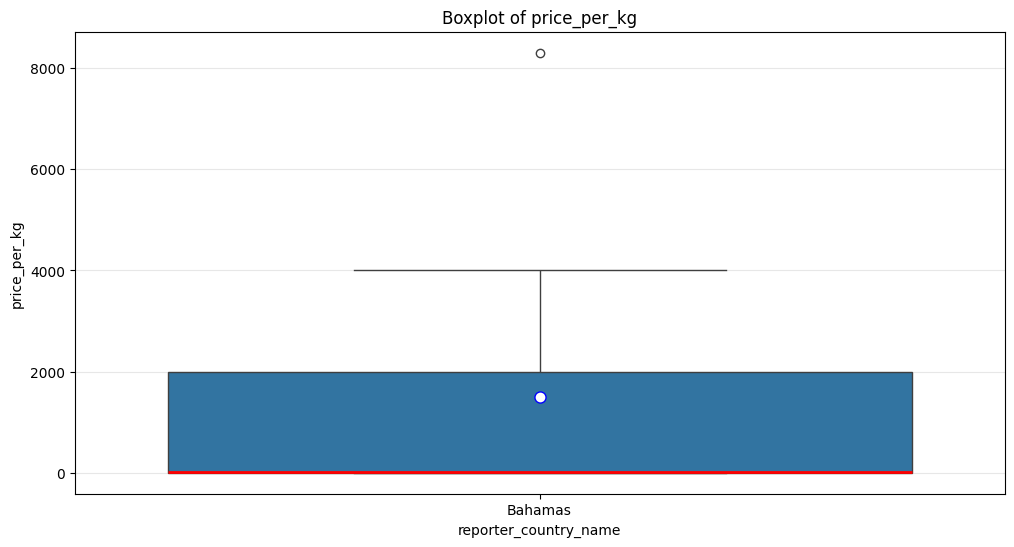

In [53]:
## Lets plot this on boxplot the median and std of price_per_kg by reporter_country_name ´Bahamas and partner_country_name USA
## Show the mean and median on the boxplot as well
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

ax = sns.boxplot(
    data=df_strg1[
        (df_strg1["reporter_country_name"] == country1)
        & (df_strg1["partner_country_name"] == country2)
    ],
    x="reporter_country_name",
    y="price_per_kg",
    showmeans=True,
    meanprops={
        "marker": "o",
        "markerfacecolor": "white",
        "markeredgecolor": "blue",
        "markersize": 8,
    },
    medianprops={
        "color": "red",
        "linewidth": 2,
    },
)

plt.title("Boxplot of price_per_kg")
plt.grid(True, axis="y", alpha=0.3)
plt.show()

In [ ]:
import importlib
import vacoda.visualization.distributions as _vd

importlib.reload(_vd)

<module 'vacoda.visualization.distribution' from '/home/pooja-saxena/PoojaVault/Professional/Workbench/Projects/Employment/Thunen/VACODA/src/vacoda/visualization/distribution.py'>

earliest_year: 2007, latest_year: 2022


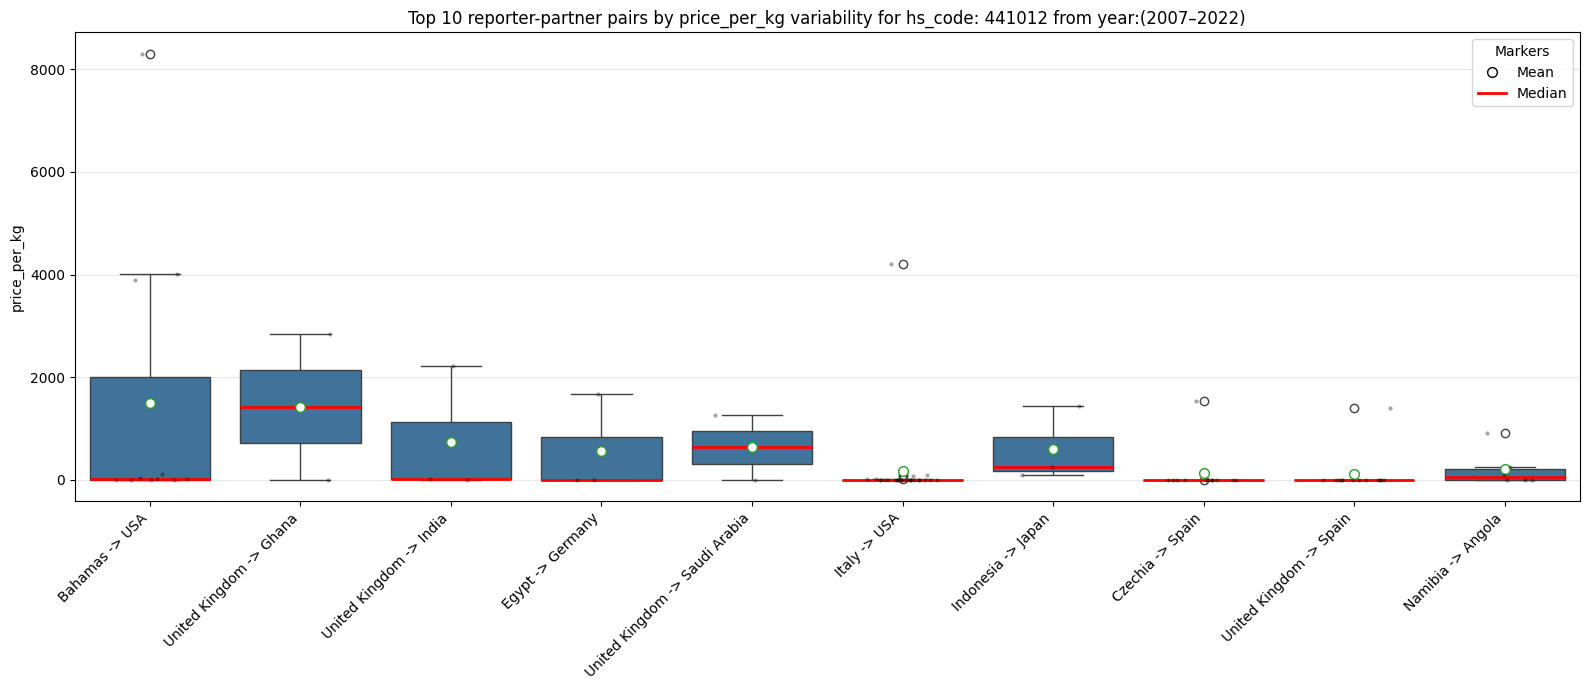

In [ ]:
import importlib
import vacoda.visualization.distributions as _vd
importlib.reload(_vd)
from vacoda.visualization.distributions import plot_top_pairs_boxplot
# --- current usage ---
plot_top_pairs_boxplot(
    df_strg1,
    value_col="price_per_kg",
    top_n=10,
    color="#3274A8",
    # title="Top 10 reporter-partner pairs by std of price_per_kg for HS_code: 441012",
)


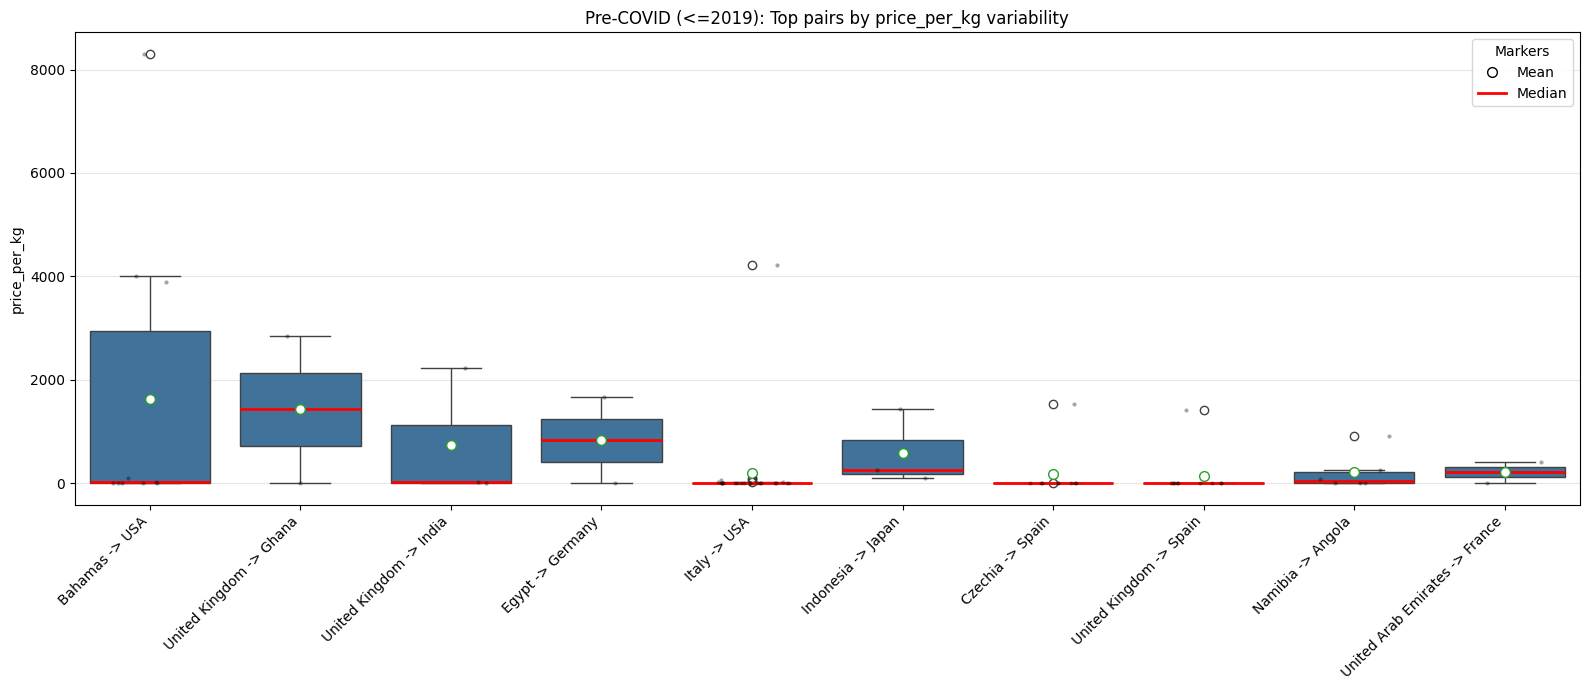

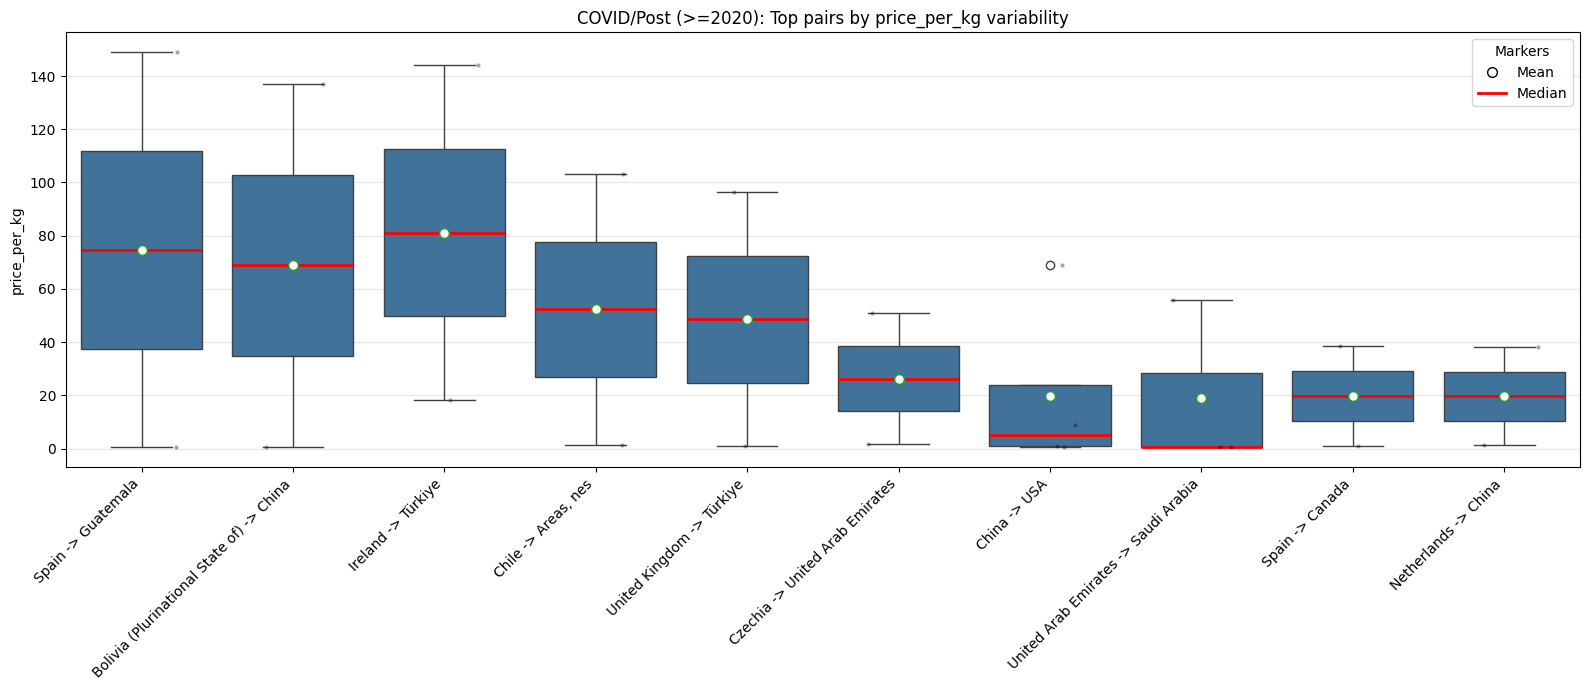

In [108]:
# Pre-COVID
plot_top_pairs_boxplot(
    df_strg1,
    value_col="price_per_kg",
    earliest_year=None,
    latest_year=2019,
    top_n=10,
    color="#3274A8",
    title="Pre-COVID (<=2019): Top pairs by price_per_kg variability",
)

# COVID/Post
plot_top_pairs_boxplot(
    df_strg1,
    value_col="price_per_kg",
    earliest_year=2020,
    latest_year=None,
    top_n=10,
    color="#3274A8",
    title="COVID/Post (>=2020): Top pairs by price_per_kg variability",
)

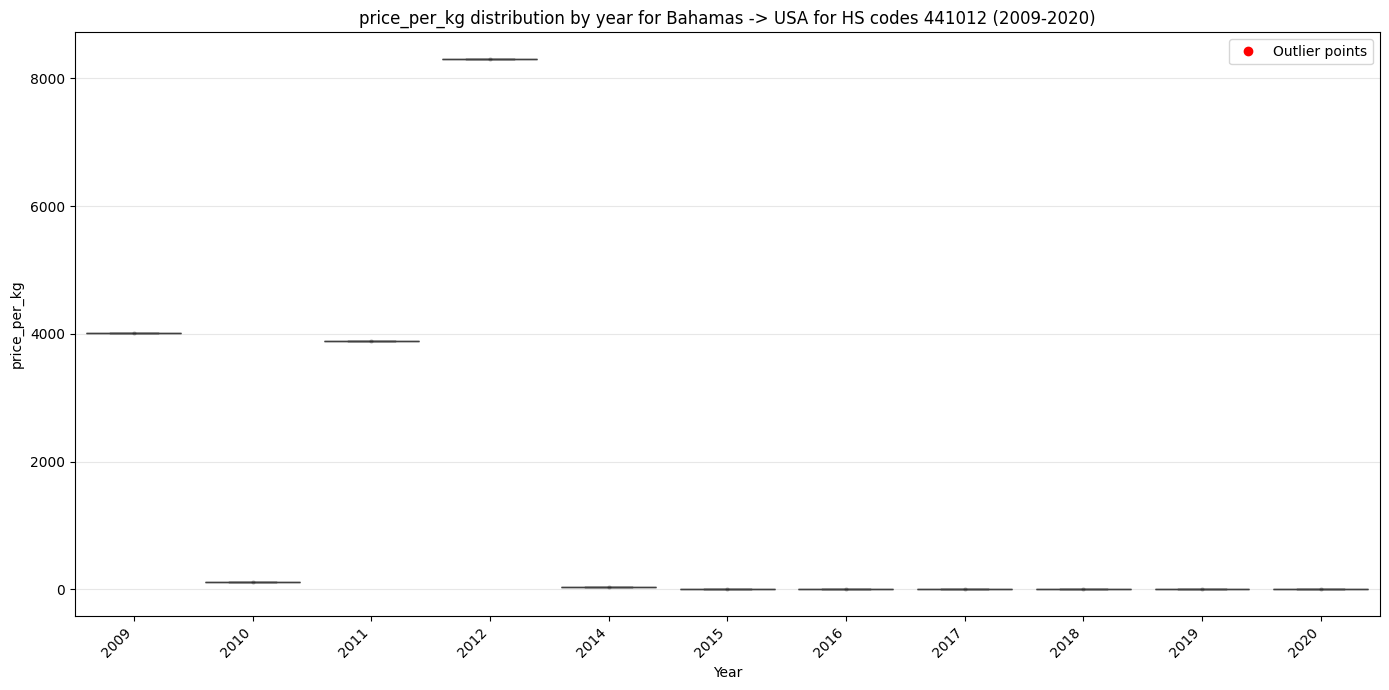

In [ ]:
from vacoda.visualization.distributions import plot_pair_price_over_years
plot_pair_price_over_years(
    df_strg1,
    reporter="Bahamas",
    partner="USA",
    value_col="price_per_kg",
    earliest_year=None,
    latest_year=None,
    draw_trend=False,
    color="#3274A8",
    #title="Price per kg over years for Bahamas -> USA",
)

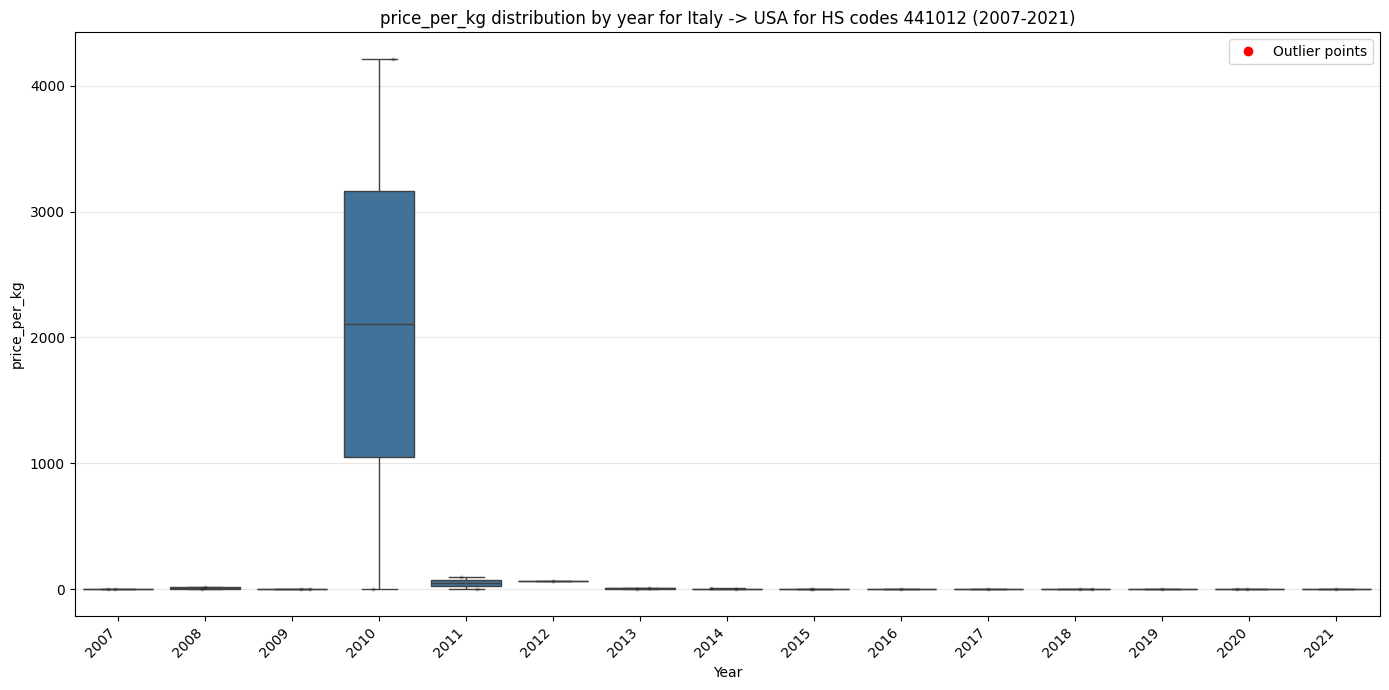

In [126]:
plot_pair_price_over_years(
    df_strg1,
    reporter="Italy",
    partner="USA",
    value_col="price_per_kg",
    earliest_year=None,
    latest_year=None,
    draw_trend=False,
    color="#3274A8",
    # title="Price per kg over years for Bahamas -> USA",
)

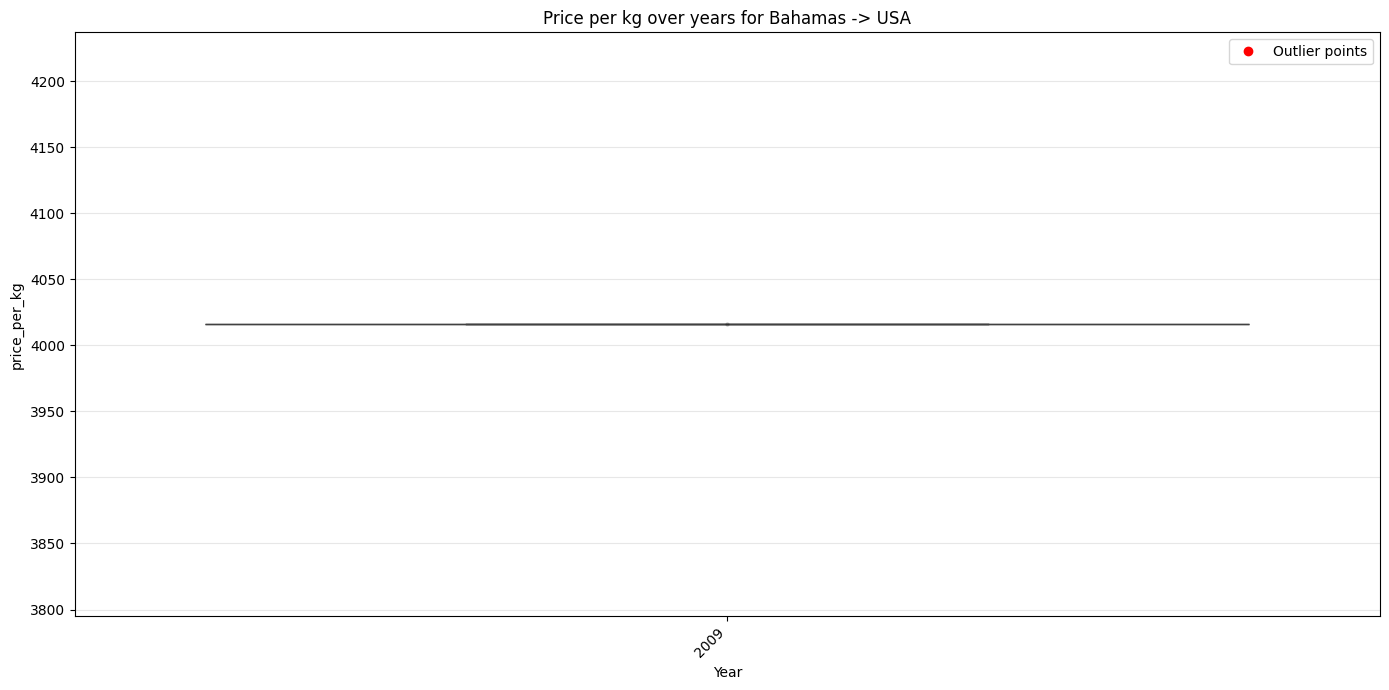

In [118]:
plot_pair_price_over_years(
    df_strg1,
    reporter="Bahamas",
    partner="USA",
    value_col="price_per_kg",
    earliest_year=2009,
    latest_year=2009,
    draw_trend=False,
    color="#3274A8",
    title="Price per kg over years for Bahamas -> USA",
)

In [77]:
df_base["commodity_code"].value_counts()

commodity_code
441012    25589
Name: count, dtype: int64

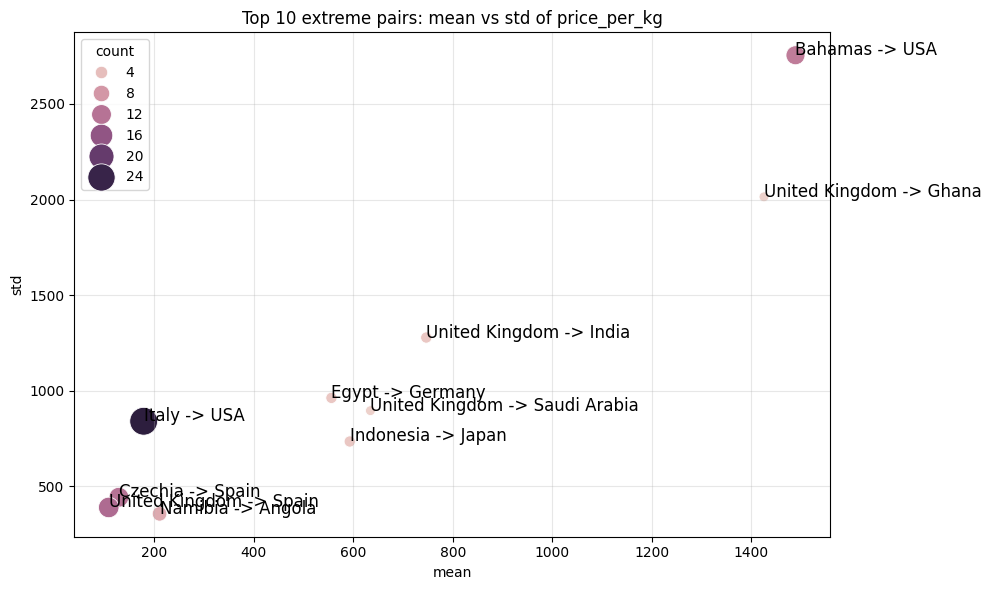

In [61]:
import matplotlib.pyplot as plt
import seaborn as sns

summary = (
    df_strg1.groupby(["reporter_country_name", "partner_country_name"])["price_per_kg"]
    .agg(["mean", "std", "count"])
    .sort_values("std", ascending=False)
    .head(10)
    .reset_index()
)

summary["pair"] = summary["reporter_country_name"] + " -> " + summary["partner_country_name"]

plt.figure(figsize=(10, 6))
ax = sns.scatterplot(
    data=summary,
    x="mean",
    y="std",
    size="count",
    hue="count",
    sizes=(50, 400),
)

for _, row in summary.iterrows():
    ax.text(row["mean"], row["std"], row["pair"], fontsize=12)

plt.title("Top 10 extreme pairs: mean vs std of price_per_kg")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

C:\Users\saxena\AppData\Local\Temp\ipykernel_10476\3661438466.py:32: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.
  ax = sns.violinplot(


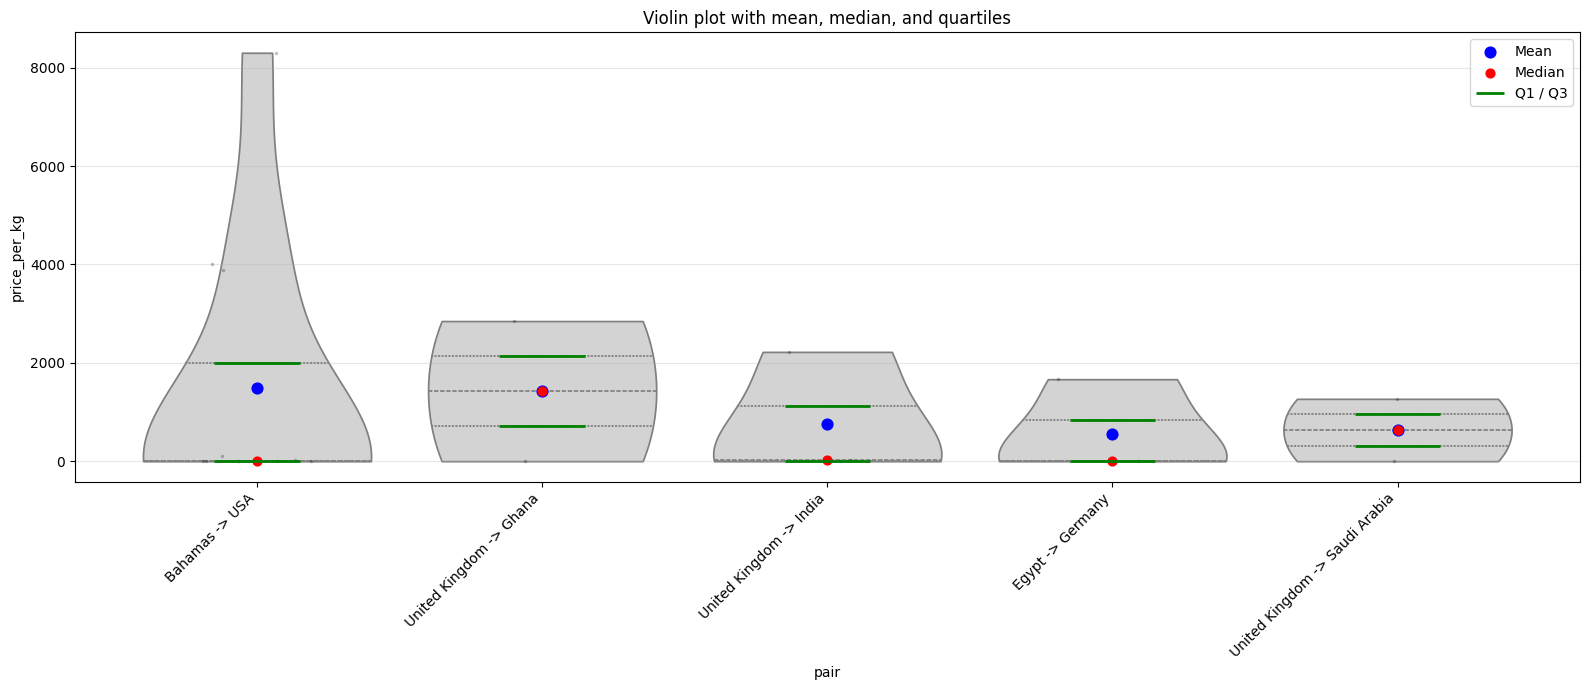

In [ ]:
## Violin plot of price_per_kg for the top 10 pairs with highest std, showing mean and median as well, and also showing the individual data points as a stripplot
## should show the transactons marker for the extreme outliers
import matplotlib.pyplot as plt
import seaborn as sns

top10 = (
    df_strg1.groupby(["reporter_country_name", "partner_country_name"])["price_per_kg"]
    .agg(["median", "std"])
    .sort_values("std", ascending=False)
    .head(5)
    .reset_index()
)

top10_pairs = set(zip(top10["reporter_country_name"], top10["partner_country_name"]))

plot_df = df_strg1[
    df_strg1[["reporter_country_name", "partner_country_name"]]
    .apply(tuple, axis=1)
    .isin(top10_pairs)
].copy()

plot_df["pair"] = (
    plot_df["reporter_country_name"] + " -> " + plot_df["partner_country_name"]
)

order = (
    top10.assign(pair=top10["reporter_country_name"] + " -> " + top10["partner_country_name"])
    ["pair"]
    .tolist()
)

plt.figure(figsize=(16, 7))

ax = sns.violinplot(
    data=plot_df,
    x="pair",
    y="price_per_kg",
    order=order,
    inner="quartile",
    cut=0,
    scale="width",
    color="lightgray",
)

sns.stripplot(
    data=plot_df,
    x="pair",
    y="price_per_kg",
    order=order,
    color="black",
    alpha=0.25,
    size=2.5,
    jitter=0.2,
)

stats = (
    plot_df.groupby("pair")["price_per_kg"]
    .agg(
        mean="mean",
        median="median",
        q25=lambda x: x.quantile(0.25),
        q75=lambda x: x.quantile(0.75),
    )
    .reindex(order)
)

for i, (_, row) in enumerate(stats.iterrows()):
    ax.scatter(i, row["mean"], color="blue", s=60, zorder=5, label="Mean" if i == 0 else "")
    ax.scatter(i, row["median"], color="red", s=40, zorder=5, label="Median" if i == 0 else "")
    ax.hlines(
        [row["q25"], row["q75"]],
        i - 0.15,
        i + 0.15,
        colors="green",
        linewidth=2,
        zorder=5,
        label="Q1 / Q3" if i == 0 else "",
    )

plt.xticks(rotation=45, ha="right")
plt.title("Violin plot with mean, median, and quartiles")
plt.grid(True, axis="y", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [48]:
country1='Bahamas'
country2='USA'

## Bahamas Reporting Country
df_strg1[(df_strg1['reporter_country_name']==country1) & (df_strg1['partner_country_name']==country2)][['year','price_per_kg','flow_code','unit_short_name', 'value_raw', 'netweight_kg','is_estimated','weight_estimated']].sort_values("year")   

,year,price_per_kg,flow_code,unit_short_name,value_raw,netweight_kg,is_estimated,weight_estimated
10936,2009,4016.000000,1,kg,8032,2.0,False,False
10763,2010,109.860000,1,kg,10986,100.0,False,False
10783,2011,3893.500000,1,kg,7787,2.0,False,False
10825,2012,8305.000000,1,kg,8305,1.0,False,False
10937,2013,NaN,1,kg,25,NaN,False,False
19171,2014,30.699413,1,kg,41874,1364.0,False,False
11890,2015,8.385555,1,kg,15790,1883.0,False,False
10938,2016,10.400933,1,kg,89188,8575.0,True,True
10939,2017,4.022527,1,kg,54819,13628.0,True,True
10940,2018,0.453554,1,kg,31239,68876.0,True,True


In [ ]:
## USA Reporting Country
df_strg1[(df_strg1['reporter_country_name']==country2) & (df_strg1['partner_country_name']==country1)][['year', 'price_per_kg','flow_code','unit_short_name', 'value_raw', 'netweight_kg','is_estimated','weight_estimated']].sort_values("year")   

,year,price_per_kg,flow_code,unit_short_name,value_raw,netweight_kg,is_estimated,weight_estimated
23863,2009,1.352623,2,kg,12271,9072.0,False,False
21875,2011,0.572470,2,kg,7070,12350.0,False,False
25022,2015,0.704884,2,kg,24045,34112.0,False,False
21876,2016,0.630852,2,kg,45844,72670.0,False,False
21877,2017,1.413228,2,kg,25000,17690.0,False,False
21530,2018,0.471817,1,kg,13376,28350.0,False,False
25486,2020,1.013352,2,kg,2960,2921.0,False,False
21923,2021,1.816278,2,kg,5378,2961.0,False,False
25023,2022,2.930862,2,kg,8775,2994.0,True,True


In [11]:
df_strg1[df_strg1['is_estimated']==True].groupby(["reporter_country_name", "partner_country_name"])["price_per_kg"].agg(["median", "std"]).sort_values("std", ascending=False).head(20)

median        std
reporter_country_name partner_country_name                     
China                 USA                   0.391419  39.514639
Italy                 China                 4.150976   5.186608
Bahamas               USA                   2.307907   4.657799
Belgium               France                0.536900   4.600045
Slovakia              Italy                 0.598220   4.483679
Nigeria               Germany               0.563338   3.937106
China                 Singapore             2.905526   3.621686
Belgium               Germany               0.527774   2.754795
                      Netherlands           0.540507   2.167281
Thailand              Cambodia              3.523577   2.150008
China                 Viet Nam              0.391960   1.916885
Finland               Estonia               1.708562   1.709633
South Africa          Lesotho               2.011108   1.582842
Finland               Sweden                1.834616   1.533028
Panama                Areas, nes            1.586197   1.149955
Philippines           USA                   0.533799   0.985378
Belgium               Czechia               0.511280   0.965985
                      Hungary               1.065832   0.914669
Canada                Türkiye               0.506884   0.883330
Australia             United Kingdom        0.705011   0.832758

### Imputation

In [ ]:
df_strg1 = prepare_weight_columns(df_base)
group_levels = build_group_levels(df_strg1)

scenarios = [
    {"min_count": 5, "max_cv": 1.0},
    {"min_count": 5, "max_cv": 1.5},
    {"min_count": 3, "max_cv": 1.0},
    {"min_count": 3, "max_cv": 1.5},
    {"min_count": 2, "max_cv": 2.0},
]

scenario_results = []

for s in scenarios:
    print(f"\n--- min_count={s['min_count']}, max_cv={s['max_cv']} ---")

    result = impute_weight(
        df_strg1,
        group_levels,
        lower_count=s["min_count"],
        max_cv=s["max_cv"],
    )

    cov = evaluate_coverage(result)

    bt = evaluate_backtest(
        df_strg1,
        group_levels,
        lower_count=s["min_count"],
        max_cv=s["max_cv"],
    )

    scenario_results.append({
        **s,
        **cov,
        **{k: v for k, v in bt.items() if k != "test_df"}
    })

scenario_summary = pd.DataFrame(scenario_results)

summary_cols = [
    "min_count",
    "max_cv",
    "coverage_%",
    "success_rate_%",
    "median_rel_error",
    "p90_rel_error",
]

display(
    scenario_summary[summary_cols]
    .sort_values(["success_rate_%", "p90_rel_error"], ascending=[False, True])
)

eligible = scenario_summary[
    scenario_summary["median_rel_error"].notna() &
    scenario_summary["p90_rel_error"].notna() &
    (scenario_summary["median_rel_error"] <= 0.50) &
    (scenario_summary["p90_rel_error"] <= 2.00)
]

if not eligible.empty:
    best = eligible.sort_values(["coverage_%", "success_rate_%"], ascending=[False, False]).iloc[0]
else:
    best = scenario_summary.sort_values(["coverage_%", "success_rate_%"], ascending=[False, False]).iloc[0]

print(f"\nBest scenario: min_count={int(best['min_count'])}, max_cv={best['max_cv']}")

df_impute1 = impute_weight(
    df_strg1,
    group_levels,
    lower_count=int(best["min_count"]),
    max_cv=float(best["max_cv"]),
    year_window=2
)


Best scenario (count, cv): 2.0 2.0
Backtest success rate: 5.6% | Median: 0.1998 | P90: 0.7612 | Mean: 0.3617 | Max: 5.1831


count    112.000000
mean       0.361707
std        0.595682
min        0.000002
25%        0.100419
50%        0.199845
75%        0.406604
max        5.183070
Name: rel_error, dtype: float64

,count,mean,std,min,25%,50%,75%,max
imputation_level,,,,,,,,
0,84.0,0.372673,0.615442,0.002574,0.104395,0.208918,0.418370,5.183070
1,28.0,0.328809,0.541214,0.000002,0.034698,0.174012,0.376978,2.826513


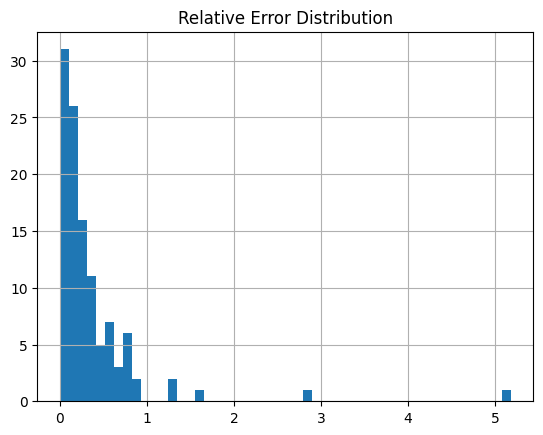

In [60]:
## Backtest on best result
print("Best scenario (count, cv):", best["min_count"], best["max_cv"])

bt = evaluate_backtest(
    df_strg1,
    group_levels,
    lower_count=int(best["min_count"]),
    max_cv=float(best["max_cv"]),
)

test_df = bt["test_df"]

display(test_df.loc[test_df["imputed_success"], "rel_error"].describe())
display(test_df.loc[test_df["imputed_success"]].groupby("imputation_level")["rel_error"].describe())

import matplotlib.pyplot as plt

test_df.loc[test_df["imputed_success"], "rel_error"].hist(bins=50)
plt.title("Relative Error Distribution")
plt.show()

Value count of 'count' column:
 count
1    17210
2     3888
3       67
Name: count, dtype: int64
max count 3


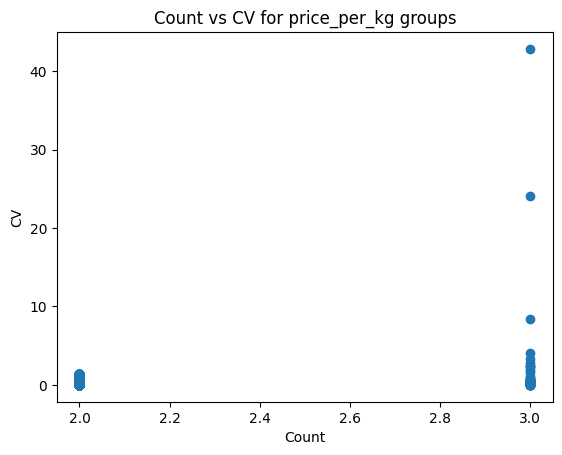

In [ ]:
import matplotlib.pyplot as plt

# Build raw reference (without filtering)
commodity_col = "commodity_code" if "commodity_code" in df_strg1.columns else "hs_code_short"
reporter_col = "reporter_code" if "reporter_code" in df_strg1.columns else "reporter_country_name"
partner_col = "partner_code" if "partner_code" in df_strg1.columns else "partner_country_name"

group_cols = [reporter_col, partner_col, "year"]

ref_raw = (
    df_strg1[df_strg1["usable_for_kg"]]
    .groupby(group_cols)["price_per_kg"]
    .agg(["median", "std", "count"])
    .reset_index()
)

ref_raw = ref_raw[ref_raw["median"] > 0].copy()
ref_raw["cv"] = ref_raw["std"] / ref_raw["median"]
print("Value count of 'count' column:\n", ref_raw["count"].value_counts().sort_index())
print("max count", ref_raw["count"].max())
# Plot
plt.figure()
plt.scatter(ref_raw["count"], ref_raw["cv"])
plt.xlabel("Count")
plt.ylabel("CV")
plt.title("Count vs CV for price_per_kg groups")
plt.show()

In [19]:
lower_count = 2
max_cv = 2

total_groups = len(ref_raw)

pass_count = (ref_raw["count"] >= lower_count)
pass_cv = (ref_raw["cv"] < max_cv)

passed_both = (pass_count & pass_cv)

print("Total groups:", total_groups)
print("Pass count condition:", pass_count.sum())
print("Pass CV condition:", pass_cv.sum())
print("Pass both:", passed_both.sum())

print("\nRejection breakdown:")
print("Rejected by count only:", ((~pass_count) & pass_cv).sum())
print("Rejected by CV only:", (pass_count & (~pass_cv)).sum())
print("Rejected by both:", ((~pass_count) & (~pass_cv)).sum())

Total groups: 21165
Pass count condition: 3955
Pass CV condition: 3946
Pass both: 3946

Rejection breakdown:
Rejected by count only: 0
Rejected by CV only: 9
Rejected by both: 17210


In [62]:
test_df.loc[
    test_df["rel_error"] > 3,
    ["reporter_country_name", "partner_country_name", "year", "value_raw"]
]

,reporter_country_name,partner_country_name,year,value_raw
1832,Italy,United Kingdom,2009,182451


In [64]:
df_impute1["good_imputation"] = (
    df_impute1["imputed_netweight_kg"].notna()
    & (~df_impute1["imputation_flag_extreme"])
)

In [65]:
(
    df_impute1.loc[df_impute1["netweight_kg"].isna()]
    .groupby(["reporter_country_name", "year"])["good_imputation"]
    .agg(["count", "sum", "mean"])
    .sort_values(["mean", "sum"], ascending=[False, False])
    .head(20)
)

count  sum  mean
reporter_country_name year                  
Canada                2007     56   56   1.0
France                2007     49   49   1.0
Belgium               2007     34   34   1.0
Canada                2015     17   17   1.0
Netherlands           2007     17   17   1.0
Canada                2016     10   10   1.0
Israel                2020      8    8   1.0
                      2007      7    7   1.0
Mexico                2017      7    7   1.0
                      2020      6    6   1.0
Singapore             2007      6    6   1.0
Finland               2019      5    5   1.0
Mexico                2019      5    5   1.0
                      2016      4    4   1.0
                      2018      4    4   1.0
Viet Nam              2012      3    3   1.0
Ireland               2018      2    2   1.0
Mexico                2015      2    2   1.0
New Zealand           2014      2    2   1.0
Aruba                 2020      1    1   1.0

In [66]:
(
    df_impute1.loc[df_impute1["good_imputation"]]
    .groupby("imputation_level")
    .size()
)

imputation_level
0    244
1     78
dtype: int64

In [51]:
df_impute1.loc[
    df_impute1["good_imputation"][df_impute1["good_imputation"] == True].index,
    ["reporter_country_name", "partner_country_name", "year","value_raw", "imputed_netweight_kg", "imputed_price", "imputation_level"]
].head(40)

,reporter_country_name,partner_country_name,year,value_raw,imputed_netweight_kg,imputed_price,imputation_level
410,Canada,Canada,2016,73087,1.295378e+05,0.564214,0
411,Canada,Canada,2016,73087,1.295378e+05,0.564214,0
437,Canada,Mexico,2016,186372,3.655315e+05,0.509866,0
491,Canada,Italy,2016,117,1.642394e+02,0.712375,0
668,Canada,USA,2016,29102166,6.030319e+07,0.482597,0
669,Canada,USA,2016,1231474126,2.551762e+09,0.482597,0
672,Canada,China,2016,290,6.614040e+02,0.438461,0
683,Canada,Germany,2016,4256,1.235384e+04,0.344508,0
719,Canada,Mexico,2016,9054,1.775761e+04,0.509866,0
902,Canada,USA,2016,15369,3.184642e+04,0.482597,0


In [ ]:
df_impute1.loc[
    (df_impute1["reporter_country_name"] == "Mexico")
    & (df_impute1["partner_country_name"] == "USA")
    & (df_impute1["year"] == 2016),
    [
        "reporter_country_name",
        "partner_country_name",
        "year",
        "value_raw",
        "netweight_kg",
        "imputed_netweight_kg",
        "imputed_price",
        "imputation_level",
        "imputation_flag_extreme",
        "good_imputation",
    ],
].head(40)

,reporter_country_name,partner_country_name,year,value_raw,netweight_kg,imputed_netweight_kg,imputed_price,imputation_level,imputation_flag_extreme,good_imputation
12516,Mexico,USA,2016,1689853,4903706.0,NaN,NaN,None,False,False
13362,Mexico,USA,2016,16459077,NaN,4.447903e+07,0.370041,0,False,True


In [ ]:
df_base2 = prepare_weight_columns(df)
group_levels = build_group_levels(df_base2)

# Add partner_country_name fallback level
commodity_col = "commodity_code" if "commodity_code" in df_base2.columns else "hs_code_short"
if df_base2[commodity_col].nunique(dropna=False) <= 1:
    group_levels.insert(2, ["partner_country_name", "year"])
else:
    group_levels.insert(3, [commodity_col, "partner_country_name", "year"])

df_base2 = impute_weight(df_base2, group_levels, lower_count=3, lower_cv=1.5)

Using commodity column: hs_code_short
